In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [ ]:
class Signal:
    """
    Classe Signal qui permet de charger et de visualiser les données météorologiques de Strasbourg Entzheim.
    """

    def __init__(self) -> None:

        self.__file_path = (
            Path.cwd() / ".." / "data" / "strasbourg_entzheim.csv"
        ).resolve()

        self.__df = pd.read_csv(filepath_or_buffer=self.__file_path, sep=",")

        # température moyenne
        self.tavg = self.__df["tavg"].to_numpy()

        # température minimum
        self.tmin = self.__df["tmin"].to_numpy()

        # température maximum
        self.tmax = self.__df["tmax"].to_numpy()

        # taux de précipitation
        self.prcp = self.__df["prcp"].to_numpy()

        # taux de neige
        self.snow = self.__df["snow"].to_numpy()

        # direction du vent
        self.wdir = self.__df["wdir"].to_numpy()

        # vitesse du vent (en km/h)
        self.wspd = self.__df["wspd"].to_numpy()

        # pic de rafale (en km/h)
        self.wpgt = self.__df["wpgt"].to_numpy()

        # pression atmosphérique (en hPa)
        self.pres = self.__df["pres"].to_numpy()

        # durée d’ensoleillement (en minutes)
        self.tsun = self.__df["tsun"].to_numpy()

        self.__data = {
            "tavg": (self.tavg, "°C"),
            "tmin": (self.tmin, "°C"),
            "tmax": (self.tmax, "°C"),
            "prcp": (self.prcp, "mm"),
            "snow": (self.snow, "mm"),
            "wdir": (self.wdir, "°"),
            "wspd": (self.wspd, "km/h"),
            "wpgt": (self.wpgt, "km/h"),
            "pres": (self.pres, "hPa"),
            "tsun": (self.tsun, "min"),
        }

    def plot_signal(self, donnée: str | tuple, start: int = 0, end: int = 365) -> None:
        """Génère le plot d'un ou plusieurs signal

        Args:
            donnée (str | tuple): Nom de la donnée ou tuple de noms de données à afficher.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        données = donnée if isinstance(donnée, tuple) else (donnée,)

        for d in données:
            if d not in self.__data:
                raise ValueError(f"{d} n'est pas une donnée valide.")

        plt.figure(figsize=(10, 5))

        for d in données:
            valeurs, unité = self.__data[d]
            x = np.asarray(valeurs[start:end], dtype=float)

            plt.plot(x, label=f"{d} ({unité})")

        plt.title(" / ".join(données))

        plt.xlabel("Temps (jours)")
        plt.ylabel("Valeur")

        plt.grid()
        plt.legend()

        plt.show()

    def spectrum(self, donnée: str, start: int = 0, end: int = 365, plot : bool = True) -> None | np.ndarray:
        """Génère le spectre d'un signal

        Args:
            donnée (str): Nom de la donnée à afficher.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.
            plot (bool, optional): Afficher le plot. Defaults to True.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        if donnée not in self.__data:
            raise ValueError(f"{donnée} n'est pas une donnée valide.")

        valeurs, unité = self.__data[donnée]

        x = np.asarray(valeurs[start:end], dtype=float)

        if np.isnan(
            x
        ).all():  # Check si les données contiennent que des valeurs manquantes
            raise ValueError(
                f"Les données de {donnée} contiennent des valeurs manquantes."
            )

        if np.isnan(x).any():
            x = (
                pd.Series(x).interpolate().to_numpy()
            )  # On remplace les valeurs manquantes par interpolation linéaire ( on prend le plus proche voisin pour les valeurs manquantes au début et à la fin )

        x = (
            x - x.mean()
        )  # On soustrait a la moyenne pour recentrer le signal autour de 0

        # Calcul de la transformée de Fourier

        amp = np.abs(np.fft.rfft(x)) / len(x)

        amp[1:] *= (
            2  # On multiplie par 2 pour les fréquences positives (sauf la fréquence 0)
        )

        if len(x) % 2 == 0:
            amp[-1] /= 2
        
        if plot:
            
            fft_freq = np.fft.rfftfreq(len(x), d=1)

            plt.figure(figsize=(10, 5))

            plt.stem(fft_freq[: len(amp)], amp, markerfmt=" ", basefmt=" ")

            plt.title(f"Spectre de {donnée} ({unité})")

            plt.xlabel("Fréquence (cycles/jour)")
            plt.ylabel("Amplitude")

            plt.grid()
            plt.show()

        else:
            
            return amp


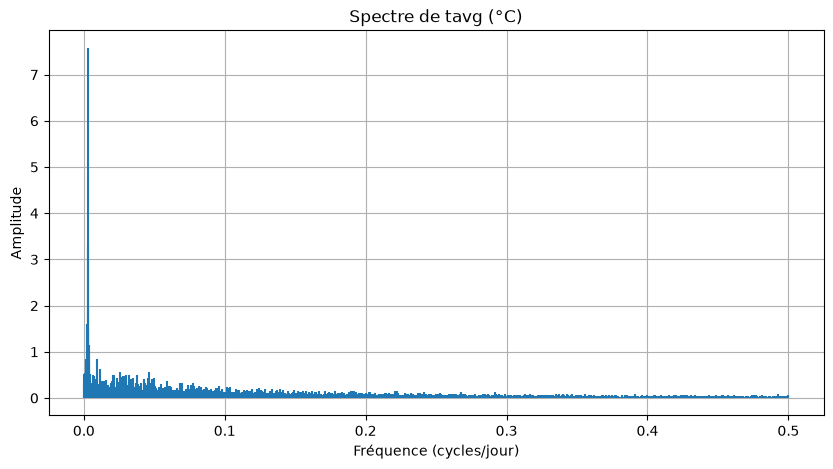

In [16]:
test = Signal()

# test.spectrum("tavg", start=0, end=5000, plot=False)
test.spectrum("tavg", start=0, end=5000, plot=True)